**QUESTION# 01: Solution**

In [ ]:
pip install pandas

In [2]:
import pandas as pd

# • Load the Data:
**Create a Pandas DataFrame with the above data.**

**Display the first few rows.**

In [3]:

var= pd.read_csv("/content/students_scores_data.csv", index_col=['Student_ID'])
var.head(5)

,Name,Math,Science,English
Student_ID,,,,
101,Student_101,98,95.0,93.0
102,Student_102,88,99.0,92.0
103,Student_103,74,63.0,82.0
104,Student_104,67,61.0,83.0
105,Student_105,80,65.0,96.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Fill the missing values:
**Fill the missing values with the average value of each column**

In [4]:
#var_c=var['Name'].mean()
var_a = var['Math'].mean()
var_b=var['Science'].mean()
var_c=var['English'].mean()

var['Math']=var['Math'].fillna(var_a)
var['Science']=var['Science'].fillna(var_b)
var['English']=var['English'].fillna(var_c)

var.head(10)


TypeError: can only concatenate str (not "int") to str

# Remove the row where all three subjects’ marks are missing

In [ ]:
var_d = var.dropna(subset=['Math', 'Science', 'English'] , how='all')
var.head(5)

,Name,Math,Science,English
Student_ID,,,,
101,Student_101,98.0,95.0,93.0
102,Student_102,88.0,99.0,92.0
103,Student_103,74.0,63.0,82.0
104,Student_104,67.0,61.0,83.0
105,Student_105,80.0,65.0,96.0


# If the score in any subject is less than zero replace it with zero.

In [ ]:
var['Math'] = var['Math'].clip(lower=0)
var['Science'] = var['Science'].clip(lower=0)
var['English'] = var['English'].clip(lower=0)

var.head(5)

,Name,Math,Science,English
Student_ID,,,,
101,Student_101,98.0,95.0,93.0
102,Student_102,88.0,99.0,92.0
103,Student_103,74.0,63.0,82.0
104,Student_104,67.0,61.0,83.0
105,Student_105,80.0,65.0,96.0


# Calculate the Average Score:

**Create a new column Average_Score that contains the average score of Math,**
**Science, and English for each student.**

In [ ]:
var['Average_Score'] = var[['Math', 'Science', 'English']].mean(axis=1)
var.head(5)

,Name,Math,Science,English,Average_Score
Student_ID,,,,,
101,Student_101,98.0,95.0,93.0,95.333333
102,Student_102,88.0,99.0,92.0,93.000000
103,Student_103,74.0,63.0,82.0,73.000000
104,Student_104,67.0,61.0,83.0,70.333333
105,Student_105,80.0,65.0,96.0,80.333333


# Determine Pass/Fail Status:
**Add another column Pass_Status. A student is considered "Pass" if their**
**Average_Score is 75 or above, otherwise "Fail".**

In [ ]:
var['Pass_Status']=var['Average_Score'].apply(lambda x: 'Pass' if x >= 75 else 'Fail')
var.head(5)

,Name,Math,Science,English,Average_Score,Pass_Status
Student_ID,,,,,,
101,Student_101,98.0,95.0,93.0,95.333333,Pass
102,Student_102,88.0,99.0,92.0,93.000000,Pass
103,Student_103,74.0,63.0,82.0,73.000000,Fail
104,Student_104,67.0,61.0,83.0,70.333333,Fail
105,Student_105,80.0,65.0,96.0,80.333333,Pass


# **Encode the Pass_Status column, 0 for Pass and 1 for Fail.**

In [ ]:
var['Pass_Status']=var['Pass_Status'].apply(lambda x: 1 if x == 'Pass' else 0)
var.head(5)

,Name,Math,Science,English,Average_Score,Pass_Status
Student_ID,,,,,,
101,Student_101,98.0,95.0,93.0,95.333333,1
102,Student_102,88.0,99.0,92.0,93.000000,1
103,Student_103,74.0,63.0,82.0,73.000000,0
104,Student_104,67.0,61.0,83.0,70.333333,0
105,Student_105,80.0,65.0,96.0,80.333333,1


# Count the total number of students pass and calculate the percentage of pass students.

In [ ]:
total_students=len(var)
total_pass = var[(var['Pass_Status'] == 0)]['Pass_Status'].count()
pass_percentage = (total_pass / total_students) * 100

print(f"\nTotal students passed: {total_pass}")
print(f"Percentage of students passed: {pass_percentage}%")


Total students passed: 16
Percentage of students passed: 32.0%


# Determine top 3 students:

**Determine the top 3 based on total marks**

In [ ]:
var['Total_Marks'] = var[['Math', 'Science', 'English']].sum(axis=1)
highest_marks = var.nlargest(3, 'Total_Marks')

print(highest_marks[['Math', 'Science', 'English', 'Total_Marks']])



            Math  Science  English  Total_Marks
Student_ID                                     
101         98.0     95.0     93.0        286.0
112         95.0     95.0     94.0        284.0
102         88.0     99.0     92.0        279.0


# Display the Updated Data:
**Show the DataFrame with the new columns.**

In [ ]:
var

,Name,Math,Science,English,Average_Score,Pass_Status
Student_ID,,,,,,
101,Student_101,98.000000,95.000000,93.000000,95.333333,1
102,Student_102,88.000000,99.000000,92.000000,93.000000,1
103,Student_103,74.000000,63.000000,82.000000,73.000000,0
104,Student_104,67.000000,61.000000,83.000000,70.333333,0
105,Student_105,80.000000,65.000000,96.000000,80.333333,1
106,Student_106,98.000000,63.000000,94.000000,85.000000,1
107,Student_107,78.000000,88.000000,0.000000,55.333333,0
108,Student_108,77.093023,77.000000,81.000000,78.364341,1
109,Student_109,70.000000,75.659574,86.000000,77.219858,1


## QUESTION# 02 --> SOLUTION:

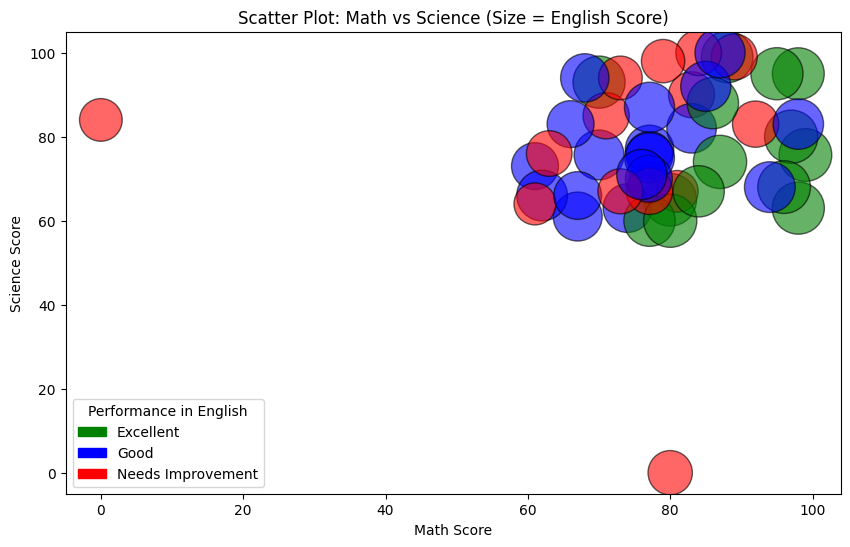

In [ ]:
import matplotlib.pyplot as plot_lib
import matplotlib.patches as mpatches

def function(score):
    if score >= 90:
        return 'Excellent'
    elif 75 <= score < 90:
        return 'Good'
    else:
        return 'Needs Improvement'

var['Performance'] = var['English'].apply(function)

sizes = var['English'] * 15

colors = var['Performance'].map({'Excellent': 'green','Good': 'blue','Needs Improvement': 'red'})
plot_lib.figure(figsize=(10,6))
plot_lib.scatter(var['Math'], var['Science'], s=sizes, c=colors, alpha=0.6, edgecolor='k')

plot_lib.xlabel('Math Score')
plot_lib.ylabel('Science Score')
plot_lib.title('Scatter Plot: Math vs Science (Size = English Score)')


elements = [mpatches.Patch(color='green', label='Excellent'),mpatches.Patch(color='blue', label='Good'),mpatches.Patch(color='red', label='Needs Improvement')]
plot_lib.legend(handles=elements, title="Performance in English")

plot_lib.show()

# QUESTION# 03 ---> SOLUTION

In [ ]:
import numpy as np

var1 = np.random.randint(0, 101, size=(6,6))
var1

array([[36, 10, 86, 43, 11,  2],
       [51, 80, 32, 54,  0, 38],
       [19, 46, 42, 56, 60, 77],
       [30, 24,  2,  3, 94, 98],
       [13, 40, 72, 19, 95, 72],
       [26, 66, 52, 67, 61, 14]])

In [ ]:
mean1 = var1.mean(axis=1)
median1 = np.median(var1,axis=1)
standard_deviation1 = var1.std(axis=1)

for i in range(6):
    print(f"Student {i}: Mean={mean1[i]}, Median={median1[i]}, Std={standard_deviation1[i]}")


Student 0: Mean=31.333333333333332, Median=23.5, Std=28.50536011973109
Student 1: Mean=42.5, Median=44.5, Std=24.315632831575655
Student 2: Mean=50.0, Median=51.0, Std=17.8232058470598
Student 3: Mean=41.833333333333336, Median=27.0, Std=39.64179892767509
Student 4: Mean=51.833333333333336, Median=56.0, Std=30.007869338262292
Student 5: Mean=47.666666666666664, Median=56.5, Std=20.45048220023729


In [ ]:
mean0 = var1.mean(axis=0)
max0 = var1.max(axis=0)
min0 = var1.min(axis=0)


for i in range(6):
    print(f"Subject {i}: Mean={mean0[i]}, Max={max0[i]}, Min={min0[i]}")




Subject 0: Mean=29.166666666666668, Max=51, Min=13
Subject 1: Mean=44.333333333333336, Max=80, Min=10
Subject 2: Mean=47.666666666666664, Max=86, Min=2
Subject 3: Mean=40.333333333333336, Max=67, Min=3
Subject 4: Mean=53.5, Max=95, Min=0
Subject 5: Mean=50.166666666666664, Max=98, Min=2


In [ ]:
mask = (var1 > 90).any(axis=1)
selected_students = var1[mask]

average_selected = selected_students.mean() if len(selected_students) > 0 else 0
print("\nSelected students (score>90 in at least one subject):")
print(selected_students)
print(f"Average score of selected students: {average_selected:.2f}")


Selected students (score>90 in at least one subject):
[[30 24  2  3 94 98]
 [13 40 72 19 95 72]]
Average score of selected students: 46.83


In [ ]:
def top_n_students(array, n):
    total_scores = array.sum(axis=1)
    top_indices = np.argsort(total_scores)[-n:]
    return top_indices

top_3 = top_n_students(scores, 3)
print("\nIndices of top 3 students based on total score:", top_3)


Indices of top 3 students based on total score: [1 3 4]


# QUESTION# 04 ---> SOLUTION

In [ ]:
import re

passwords = ["Abc@1234","password","Pass123","Strong@Pass1","weakpass123"]

def check_password_strength(password):

    pattern = r'^(?=.*[a-z])(?=.*[A-Z])(?=.*\d)(?=.*[@$!%*?&]).{8,}$'

    if re.match(pattern, password):
        return "Strong"
    else:
        return "Weak"

# 3️⃣ Check each password
for i in passwords:
    result = check_password_strength(i)
    print(f"Password: {i} → {result}")


Password: Abc@1234 → Strong
Password: password → Weak
Password: Pass123 → Weak
Password: Strong@Pass1 → Strong
Password: weakpass123 → Weak
